## Import libaries

In [469]:
import pandas as pd
import numpy as np

import a bigger dataset for us to apply methods learnt from the different sections.

We are using the 'StackOverflow Survey Data 2026'.

In [470]:
large_df = pd.read_csv('results.txt')
schema_df = pd.read_csv('schema.txt')

/var/folders/8j/5y8s8l5j7qnc7bjs1pssrnb40000gn/T/ipykernel_3031/634978724.py:1: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  large_df = pd.read_csv('results.txt')


## Part 1: Dataframs and Series Basics - Selecting Rows and Columns

Content: 
1. How to think about dataframes and series
2. Filtering dataframes by columns
3. Get column names
4. Getting rows and values (LOC and ILOC)

Main methods covered: 
* `loc` and `iloc`
* `.DataFrame()`
* `.to_list()`
* `value_counts()`

The most intuitive sense of how to imagine a dataframe is to imagine them as a dictionary where the **keys** are the column headers and the **values (given as a list)** are the respective columns.


In [471]:
people = {
    'first': ['Corey', 'Jane', 'John'],
    'last': ['Schafer', 'Doe', 'Doe'],
    'email': ['CoreyMSchafer@gmail.com', 'JaneDoe@email.com', 'JohnDoe@email.com']
}

In [472]:
people['email']

['CoreyMSchafer@gmail.com', 'JaneDoe@email.com', 'JohnDoe@email.com']

We use **.DataFrame('data')** to convert the dict into a pandas dataframe.

In [473]:
df = pd.DataFrame(people)
df

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com
2,John,Doe,JohnDoe@email.com


Similarly to how we access the values in a dictionary using it's key, we do the same to access rows of a dataframe with the column header. 

Note: We get back a **series** data type, instead of list. 

**Facts about dataframes:**
* They are 2-dimensional as they contains rows and columns
* Series are 1-dimensional as they contain only rows 
* A dataframe is essentially a **collection** of series (container)
* Both series and dataframes have **indexes**

In [474]:
print(df['email'])
print(type(df['email']))

0    CoreyMSchafer@gmail.com
1          JaneDoe@email.com
2          JohnDoe@email.com
Name: email, dtype: object
<class 'pandas.core.series.Series'>


### Filtering by columns

We filter the dataframe by columns by passing in a **list of column names**.

This method returns a *dataframe*.

In [475]:
df[['last', 'email']]

,last,email
0,Schafer,CoreyMSchafer@gmail.com
1,Doe,JaneDoe@email.com
2,Doe,JohnDoe@email.com


### Get column names

Use **.columns** to check all columns in our dataframe. This method returns a pandas *index* object which behaves simarly to a list. 

We can convert the *index* to a *list* by applying **.to_list()**.

In [476]:
df.columns

Index(['first', 'last', 'email'], dtype='object')

In [477]:
df.columns.to_list()

['first', 'last', 'email']

### Get rows (LOC and ILOC)

To get specific rows we use **.loc (location)** and **iloc (integer location)**.

`.loc` selects by **label** (the names in the index and columns). `.iloc` selects by **position** (integer counts starting at 0). Both take [rows, columns].


When our output is a **single row:**
* We get a *series* where the **index are the column names** and **rows are the respective data**.

When our output has **multiple rows:**
* We get a *dataframe* a **filtered dataframe**.

In [478]:
# single row 
df.iloc[0] 

first                      Corey
last                     Schafer
email    CoreyMSchafer@gmail.com
Name: 0, dtype: object

In [479]:
# multiple rows (pass in a list)
df.iloc[[0,1]]

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com


In [480]:
# filter by [row, column] 
df.iloc[[0,1], 2] # first two rows [0, 1] and third column 2 

0    CoreyMSchafer@gmail.com
1          JaneDoe@email.com
Name: email, dtype: object

In [481]:
# single row 
# note: passing 0 works into loc in this case works as the label (index) is 0.
df.loc[0]

first                      Corey
last                     Schafer
email    CoreyMSchafer@gmail.com
Name: 0, dtype: object

In [482]:
# multiple rows
df.loc[[0,1]]

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com


In [483]:
# filter by [row, column]
df.loc[[0,1], ['email', 'last']] # rows = [0,1] and cols = ['email', 'last']

,email,last
0,CoreyMSchafer@gmail.com,Schafer
1,JaneDoe@email.com,Doe


### Working with a larger dataset

Applying some of the methods we learnt to a larger dataset

In [484]:
# take a look at first 5 rows
large_df.head()

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


In [485]:
# inspect rough shape of data
large_df.shape

(49191, 172)

In [486]:
# see all available columns
large_df.columns.to_list()

['ResponseId',
 'MainBranch',
 'Age',
 'EdLevel',
 'Employment',
 'EmploymentAddl',
 'WorkExp',
 'LearnCodeChoose',
 'LearnCode',
 'LearnCodeAI',
 'AILearnHow',
 'YearsCode',
 'DevType',
 'OrgSize',
 'ICorPM',
 'RemoteWork',
 'PurchaseInfluence',
 'TechEndorseIntro',
 'TechEndorse_1',
 'TechEndorse_2',
 'TechEndorse_3',
 'TechEndorse_4',
 'TechEndorse_5',
 'TechEndorse_6',
 'TechEndorse_7',
 'TechEndorse_8',
 'TechEndorse_9',
 'TechEndorse_13',
 'TechEndorse_13_TEXT',
 'TechOppose_1',
 'TechOppose_2',
 'TechOppose_3',
 'TechOppose_5',
 'TechOppose_7',
 'TechOppose_9',
 'TechOppose_11',
 'TechOppose_13',
 'TechOppose_16',
 'TechOppose_15',
 'TechOppose_15_TEXT',
 'Industry',
 'JobSatPoints_1',
 'JobSatPoints_2',
 'JobSatPoints_3',
 'JobSatPoints_4',
 'JobSatPoints_5',
 'JobSatPoints_6',
 'JobSatPoints_7',
 'JobSatPoints_8',
 'JobSatPoints_9',
 'JobSatPoints_10',
 'JobSatPoints_11',
 'JobSatPoints_13',
 'JobSatPoints_14',
 'JobSatPoints_15',
 'JobSatPoints_16',
 'JobSatPoints_15_TEXT',
 

let's now try to grab the responses for column `RemoteWork`.

In [487]:
large_df['RemoteWork']

0                                                   Remote
1        Hybrid (some in-person, leans heavy to flexibi...
2                                                      NaN
3                                                   Remote
4                                                      NaN
                               ...                        
49186                                                  NaN
49187                                                  NaN
49188    Hybrid (some in-person, leans heavy to flexibi...
49189                                                  NaN
49190                                                  NaN
Name: RemoteWork, Length: 49191, dtype: object

Apply the **.value_counts()** method to get the unique counts of all elements in the series. 

In [488]:
large_df['RemoteWork'].value_counts()

RemoteWork
Remote                                                                          10931
Hybrid (some remote, leans heavy to in-person)                                   6732
In-person                                                                        6042
Hybrid (some in-person, leans heavy to flexibility)                              5831
Your choice (very flexible, you can come in when you want or just as needed)     4244
Name: count, dtype: int64

grabbing specific rows

In [489]:
# first person (row) data
large_df.loc[0]

ResponseId                                                           1
MainBranch                              I am a developer by profession
Age                                                    25-34 years old
EdLevel                Master’s degree (M.A., M.S., M.Eng., MBA, etc.)
Employment                                                    Employed
                                            ...                       
AIAgentExtWrite                                                    NaN
AIHuman                                When I don’t trust AI’s answers
AIOpen                           Troubleshooting, profiling, debugging
ConvertedCompYearly                                            61256.0
JobSat                                                            10.0
Name: 0, Length: 172, dtype: object

In [490]:
# first person and 'RemoteWork' column
large_df.loc[0, 'RemoteWork']

'Remote'

We can apply slicing with `loc` and `iloc`.

* When we use slicing we don't use brackets
* Slicing is **inclusive** of endpoints

In [491]:
# Applying slicing to rows
large_df.loc[0:2, 'RemoteWork']

0                                               Remote
1    Hybrid (some in-person, leans heavy to flexibi...
2                                                  NaN
Name: RemoteWork, dtype: object

In [492]:
# Applying slicing to columns
large_df.loc[0:2, 'RemoteWork':'TechEndorseIntro']

,RemoteWork,PurchaseInfluence,TechEndorseIntro
0,Remote,"Yes, I influenced the purchase of a substantia...",Work
1,"Hybrid (some in-person, leans heavy to flexibi...",No,Personal Project
2,NaN,No,Work


## Part 2: Indexes - How to Set, Reset and Use Indexes

Content: 
1. Setting indexes
2. Getting indexes
3. Resetting indexes
4. Understanding the uses of setting indexes and interactions with `loc`
5. Sorting indexes

Main methods covered:
* `set_index()`
* `reset_index()`
* `sort_index()`

*indexes* by default are the range of numbers [0, n] on the far left of the dataframe. 

They are usually unique (not enforced) **integer identifiers for each row** in the dataframe. 

In [493]:
df

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com
2,John,Doe,JohnDoe@email.com


### Setting the index

We can change the index to values in a column using **.set_index('column name')**.

Note: Unless specified pandas **does not** apply the changes directly to our dataframe.

In [494]:
# set index to email column
df.set_index('email')
df

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com
2,John,Doe,JohnDoe@email.com


To keep the changes we pass **inplace = True**.

In [495]:
df.set_index('email', inplace=True)
df

,first,last
email,,
CoreyMSchafer@gmail.com,Corey,Schafer
JaneDoe@email.com,Jane,Doe
JohnDoe@email.com,John,Doe


### Getting the indexes

Apply **.index** to get all the indexes in our dataframe. This method returns a pandas *index* data type. 


Note: To get the indexes as a list, we can apply **to_list()**.

In [496]:
df.index

Index(['CoreyMSchafer@gmail.com', 'JaneDoe@email.com', 'JohnDoe@email.com'], dtype='object', name='email')

In [497]:
df.index.to_list()

['CoreyMSchafer@gmail.com', 'JaneDoe@email.com', 'JohnDoe@email.com']

Why are indexes important?
* indexes serve as a **"unique" indentifier** for rows in our dataframe
* `loc` uses these labels to filter our dataframe; naming the index as a value which is more representative (like email etc.) makes it **easy to grab respective rows** when we need them

In [498]:
# get data for the following email
print(df.loc['CoreyMSchafer@gmail.com'])

# get last name for the following email 
print()
print(df.loc['CoreyMSchafer@gmail.com', 'last'])

first      Corey
last     Schafer
Name: CoreyMSchafer@gmail.com, dtype: object

Schafer


If we want to search by **integer location** we can still use `iloc`

In [499]:
# first row
df.iloc[0]

first      Corey
last     Schafer
Name: CoreyMSchafer@gmail.com, dtype: object

### Reset index

Apply **.reset_index()** to return the index back to default numerical range.

In [500]:
df.reset_index(inplace=True)
df

,email,first,last
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


### Working with a larger dataset

If we know a specific column (ID, name etc.) that we want as our index. We can set that column to be index when loading in our data by applying **index_col='column name'**.  

In [501]:
# set 'ResponseId' as index
large_df = pd.read_csv('results.txt', index_col='ResponseId')
large_df.head()

/var/folders/8j/5y8s8l5j7qnc7bjs1pssrnb40000gn/T/ipykernel_3031/2421846051.py:2: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  large_df = pd.read_csv('results.txt', index_col='ResponseId')


,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,AILearnHow,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
ResponseId,,,,,,,,,,,,,,,,,,,,,
1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps,...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Technical ...,...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",AI CodeGen tools or AI-enabled apps;Videos (no...,...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",Technical documentation (is generated for/by t...,...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


now if we want the first respondent, we can simply call `loc` and pass in the first index label

In [502]:
large_df.loc[1]

MainBranch                              I am a developer by profession
Age                                                    25-34 years old
EdLevel                Master’s degree (M.A., M.S., M.Eng., MBA, etc.)
Employment                                                    Employed
EmploymentAddl         Caring for dependents (children, elderly, etc.)
                                            ...                       
AIAgentExtWrite                                                    NaN
AIHuman                                When I don’t trust AI’s answers
AIOpen                           Troubleshooting, profiling, debugging
ConvertedCompYearly                                            61256.0
JobSat                                                            10.0
Name: 1, Length: 171, dtype: object

In [503]:
schema_df.head()

,qid,qname,question,type,sub,sq_id
0,QID18,TechEndorse_1,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.0
1,QID18,TechEndorse_2,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.0
2,QID18,TechEndorse_3,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.0
3,QID18,TechEndorse_4,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.0
4,QID18,TechEndorse_5,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.0


Applying indexing to a real world context. I can set `qname` to be the index to allow for easy look up for `question` column using **loc**.

In [504]:
schema_df.set_index('qname', inplace=True)
schema_df.head()

,qid,question,type,sub,sq_id
qname,,,,,
TechEndorse_1,QID18,What attracts you to a technology or causes yo...,RO,AI integration or AI Agent capabilities,1.0
TechEndorse_2,QID18,What attracts you to a technology or causes yo...,RO,Easy-to-use API,2.0
TechEndorse_3,QID18,What attracts you to a technology or causes yo...,RO,Robust and complete API,3.0
TechEndorse_4,QID18,What attracts you to a technology or causes yo...,RO,Customizable and manageable codebase,4.0
TechEndorse_5,QID18,What attracts you to a technology or causes yo...,RO,Reputation for quality,5.0


Now to search for the 'question' for 'RemoteWork' column we used previously. 

In [505]:
# pass in [index_label, 'question' column]
print(schema_df.loc['RemoteWork', 'question'])

# another example for 'AIAgentKnowledge'
print(schema_df.loc['AIAgentKnowledge', 'question'])

Which best describes your current work situation?
You indicated you use or develop AI agents as part of your development work.  Have you used any of the following tools for AI agent memory or data management in the past year?


To sort the index alphabetically, we apply **.sort_index()**.

We can pass **ascending=True / False** to sort by ascending or descending order.

In [506]:
# sort by ascending order
schema_df.sort_index()

,qid,question,type,sub,sq_id
qname,,,,,
AIAcc,QID80,How much do you trust the accuracy of the outp...,MC,NaN,NaN
AIAgentChallenges,QID88,To what extent do you agree with the following...,Matrix,NaN,NaN
AIAgentChange,QID83,Have AI tools or AI agents changed how you com...,MC,NaN,NaN
AIAgentExtWrite,QID104,"Was the out-of-the-box agents, copilots or ass...",TE,NaN,NaN
AIAgentExternal,QID92,You indicated you use or develop AI agents as ...,MC,NaN,NaN
...,...,...,...,...,...
WebframeChoice,QID47,Did you work with web frameworks and web techn...,MC,NaN,NaN
WebframeHaveEntry,QID58,Were the web frameworks and web technologies y...,TE,NaN,NaN
WebframeWantEntry,QID59,Were the web frameworks and web technologies y...,TE,NaN,NaN


## Part 3: Filtering - Using Conditionals to Filter Rows and Columns

Filtering is a crucial part of using pandas as most workflows start with filtering through to the data that we want.

Content: 
1. Filter (boolean) masking; How to apply mask with `loc`
2. Create multiple filters - Using '&' and '|' operators
3. Create multiple filters - Using 'isin()' 
4. Creating filters using string methods

**Important:** Understand that **boolean series / dataframes** can be created and passed into `loc` or directly in the df to apply the filter. This means any method that is able to create these boolean data structures can essentially be used to create filters. 

Main methods used: 
* `loc`
* `.isin()`
* `.str.contains()`

### Filter (boolean) masking

We can apply a **filter mask** by filtering a column for a specific condition below. 

This method returns a **boolean series** where True corresponds to elements that meet our criteria and False elements that don't.

In [507]:
# applying a filter mask
filt = (df['last'] == 'Doe')
filt

0    False
1     True
2     True
Name: last, dtype: bool

We can then **pass this filter into our dataframe** to apply the filter.

The result grabs us the **rows** which meet our filter conditions. 

In [508]:
# applying the filter
df[filt]

,email,first,last
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


In [509]:
# alternatively we can also apply the filter directly 
df[(df['last'] == 'Doe')]

,email,first,last
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


We can then pass the filter into `loc` to **further filter by column / columns.** 

In [510]:
# passing the boolean filter into 'loc' and filtering for only 'email'
df.loc[filt, 'email']

1    JaneDoe@email.com
2    JohnDoe@email.com
Name: email, dtype: object

### Multiple filters - Using `&` and `|` operators 

When we apply multiple filters we need to be aware that typical python `and` and `or` operators **don't work** with pandas. 

We instead use:
* `&`: and
* `|`: or 

In [511]:
# applying multiple filters using the '&' operator
filt = (df['last'] == 'Doe') & (df['first'] == 'John')
df[filt]

,email,first,last
2,JohnDoe@email.com,John,Doe


In [512]:
# applying multiple filters using the '|' operator
filt = (df['last'] == 'Schafer') | (df['first'] == 'John') 
df.loc[filt]

,email,first,last
0,CoreyMSchafer@gmail.com,Corey,Schafer
2,JohnDoe@email.com,John,Doe


We can also **negate the filter** by passing in a `~`.

In [513]:
# negation of the previous filter
df.loc[~filt]

,email,first,last
1,JaneDoe@email.com,Jane,Doe


### Working with a larger dataset

In [514]:
# resetting the index from the previous section
large_df.reset_index(inplace=True)
schema_df.reset_index(inplace=True)
large_df.columns.sort_values().to_list()

['AIAcc',
 'AIAgentChallengesNeutral',
 'AIAgentChallengesSomewhat agree',
 'AIAgentChallengesSomewhat disagree',
 'AIAgentChallengesStrongly agree',
 'AIAgentChallengesStrongly disagree',
 'AIAgentChange',
 'AIAgentExtWrite',
 'AIAgentExternal',
 'AIAgentImpactNeutral',
 'AIAgentImpactSomewhat agree',
 'AIAgentImpactSomewhat disagree',
 'AIAgentImpactStrongly agree',
 'AIAgentImpactStrongly disagree',
 'AIAgentKnowWrite',
 'AIAgentKnowledge',
 'AIAgentObsWrite',
 'AIAgentObserveSecure',
 'AIAgentOrchWrite',
 'AIAgentOrchestration',
 'AIAgent_Uses',
 'AIAgents',
 'AIComplex',
 'AIExplain',
 'AIFrustration',
 'AIHuman',
 'AILearnHow',
 'AIModelsAdmired',
 'AIModelsChoice',
 'AIModelsHaveEntry',
 'AIModelsHaveWorkedWith',
 'AIModelsWantEntry',
 'AIModelsWantToWorkWith',
 'AIOpen',
 'AISelect',
 'AISent',
 'AIThreat',
 'AIToolCurrently mostly AI',
 'AIToolCurrently partially AI',
 "AIToolDon't plan to use AI for this task",
 'AIToolPlan to mostly use AI',
 'AIToolPlan to partially use AI'

Let's start by filtering `ConvertedCompYearly` to find people with **high salaries**.

In [515]:
# create a boolean mask
high_salary = (large_df['ConvertedCompYearly'] > 70000)

# pass in the filter into method `loc`
large_df.loc[high_salary]

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
5,6,I am a developer by profession,45-54 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc....",15.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,GitHub Copilot,NaN,When I have ethical or security concerns about...,designing the architecture in the new domain,120000.0,7.0
7,8,I am a developer by profession,35-44 years old,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",Employed,Engaged in paid work (20-29 hours per week);Tr...,22.0,"Yes, I am not new to coding but am learning ne...",Books / Physical media;Technical documentation...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I want to learn best practices;When I wan...,"Innovation, system design",72000.0,6.0
22,23,I am a developer by profession,25-34 years old,Some college/university study without earning ...,Employed,None of the above,7.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,Technical knowledge. As AI slides into the for...,87500.0,9.0
25,26,I am a developer by profession,55-64 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,37.0,"Yes, I am not new to coding but am learning ne...",Stack Overflow or Stack Exchange;Technical doc...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;GitHub Copilot;Replit,NaN,When I don’t trust AI’s answers;When I want to...,Choosing the best solutions. Converting user r...,108913.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49066,49067,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,"Caring for dependents (children, elderly, etc.)",19.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,138470.0,6.0
49075,49076,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","No, I learned something that was not related t...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,82366.0,2.0
49083,49084,"I am not primarily a developer, but I write co...",35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,22.0,"No, I am not new to coding and did not learn n...",NaN,"No, I didn't spend time learning in the past year",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,188000.0,NaN
49084,49085,"I am not primarily a developer, but I write co...",55-64 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Not employed,None of the above,46.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"No, I didn't spend time learning in the past year",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,119000.0,NaN


Let's further filter to only columns we want such as `Country`, `LanguagesHaveWorkedWith` and `ConvertedCompYearly`.

In [516]:
large_df.loc[high_salary, ['Country', 'LanguageHaveWorkedWith', 'ConvertedCompYearly']]

,Country,LanguageHaveWorkedWith,ConvertedCompYearly
1,Netherlands,Java,104413.0
5,Ukraine,Java;Scala,120000.0
7,Ukraine,Bash/Shell (all shells);HTML/CSS;JavaScript;Py...,72000.0
22,United States of America,C#;C++;JavaScript;Python;Visual Basic (.Net),87500.0
25,United Kingdom of Great Britain and Northern I...,Bash/Shell (all shells);JavaScript;Perl;SQL;Ty...,108913.0
...,...,...,...
49066,Australia,HTML/CSS;JavaScript;TypeScript,138470.0
49075,United Kingdom of Great Britain and Northern I...,NaN,82366.0
49083,United States of America,NaN,188000.0
49084,United States of America,NaN,119000.0


### Multiple filters - using `isin()`

An alternative we can do instead of writing an extremely long `&` filter statement is to make use of the **.isin()** method. 

**isin('values')** checks if each element in the *dataframe* contains the values inputted. The method returns a *dataframe* of the **same shape with boolean values** (similar to a boolean mask!).

Let's say I want to filter for a select number of countries. We can do the following:

In [517]:
# create a list of countries I want
countries = ['United States of America', 'India', 'Australia', 'Germany', 'Canada']

# create a boolean mask for 'Countries' column using 'isin()'
filt = large_df['Country'].isin(countries)
filt

0        False
1        False
2        False
3        False
4        False
         ...  
49186    False
49187    False
49188    False
49189    False
49190    False
Name: Country, Length: 49191, dtype: bool

In [518]:
# apply the filter to dataframe
large_df.loc[filt, 'Country']

13                          India
15                          India
16                      Australia
18                        Germany
21       United States of America
                   ...           
49157    United States of America
49175                     Germany
49177    United States of America
49178                     Germany
49180                      Canada
Name: Country, Length: 14914, dtype: object

### Filter strings

Sometimes we may want to filter for a specific keyword contained in a string. 

We apply **.str.contains('values')**, which test if a elements in the *series* contains the values inputted. This method returns a **boolean series** (again simialar to a boolean mask!). 

note: we can pass **na=False** as a parameter to ensure missing / na values return as 'False' instead of NaN. 

We want to filter for people who have worked with 'Python' from the column `LanguageHaveWorkedWith`.

In [519]:
# notice 'python' is contained within a string
large_df['LanguageHaveWorkedWith']

0                         Bash/Shell (all shells);Dart;SQL
1                                                     Java
2                      Dart;HTML/CSS;JavaScript;TypeScript
3                                          Java;Kotlin;SQL
4        C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...
                               ...                        
49186                                                  NaN
49187                                                  NaN
49188                                                  NaN
49189                                                  NaN
49190                                                  NaN
Name: LanguageHaveWorkedWith, Length: 49191, dtype: object

In [520]:
# apply '.str.contains()' to create the filter
filt = large_df['LanguageHaveWorkedWith'].str.contains('Python', na=False)
filt

0        False
1        False
2        False
3        False
4         True
         ...  
49186    False
49187    False
49188    False
49189    False
49190    False
Name: LanguageHaveWorkedWith, Length: 49191, dtype: bool

In [521]:
# apply the filter to dataframe
large_df.loc[filt, 'LanguageHaveWorkedWith']

4        C;C#;C++;Delphi;HTML/CSS;Java;JavaScript;Lua;P...
7        Bash/Shell (all shells);HTML/CSS;JavaScript;Py...
8                                        Java;Python;Scala
15       Ada;Assembly;C;C#;C++;COBOL;Dart;Delphi;Elixir...
17                          HTML/CSS;JavaScript;Python;SQL
                               ...                        
49143            HTML/CSS;JavaScript;Python;SQL;TypeScript
49145    Assembly;Bash/Shell (all shells);C;C++;Python;...
49175    Bash/Shell (all shells);C#;C++;GDScript;HTML/C...
49176    Bash/Shell (all shells);HTML/CSS;JavaScript;Py...
49177    Bash/Shell (all shells);HTML/CSS;Lisp;PowerShe...
Name: LanguageHaveWorkedWith, Length: 18466, dtype: object

## Part 4: Updating Rows and Columns - Modifying Data Within DataFrames

Contents: 
1. Updating column names
2. Updating rows and specific values
3. Applying bulk data changes
4. Mapping and replacing values

Main methods used: 
* `.columns`: see all column names
* `.str.replace`: string method to replace 'spaces' 
* `.rename`: renaming specific columns
* `.at`: replacing one specific value (more efficient than 'loc')
* `.apply`: apply a function to series in a dataframe or each value in a series
* `.map`: apply a function to each value in a dataframe or replacing values
* `.replace`: replace values without leaving NaN

### Updating all column names at once

We update column names using a **list** of our new column names.

In [522]:
# initial look at column names
df.columns

Index(['email', 'first', 'last'], dtype='object')

In [523]:
# updating the column names
df.columns = ['email', 'first_name', 'last_name']
df

,email,first_name,last_name
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


Since we are **list**, we can also apply **list comprehension** to update the column names. 


In [524]:
# apply upper() to make the column caps
df.columns = [name.upper() for name in df.columns]
df

,EMAIL,FIRST_NAME,LAST_NAME
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


Normally we will also want to replace 'spaces' in column names with '_'. 

We apply **.str.replace()** to achieve this. 

In [525]:
# we replace '_' with ' ' as we alr have '_'
df.columns = df.columns.str.replace('_', ' ')
df

,EMAIL,FIRST NAME,LAST NAME
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


In [526]:
# reverting everything back 
df.columns = [x.lower() for x in df.columns]
df.columns = df.columns.str.replace(' ', '_')
df

,email,first_name,last_name
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


### Updating specific column names

To update a specific column, we apply `.rename(columns={'old name': 'new name'})`

In [527]:
# applying rename() method
df.rename(columns={'first_name': 'first', 
                   'last_name': 'last'}, inplace=True)
df

,email,first,last
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


### Updating rows and specific values

Similarly to updating columns, we can update **row values** using a list and `loc`.

Important note: We **must** use the methods `loc` or `at` below when updating values, not doing so will result in an error and the dataframe will not update.

In [528]:
print(df.loc[2])

# updating row values
df.loc[2] = ['JohnSmith@email.com', 'John', 'Smith']

df

email    JohnDoe@email.com
first                 John
last                   Doe
Name: 2, dtype: object


,email,first,last
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnSmith@email.com,John,Smith


With the same method, we can update **specific values**.

In [529]:
# updating specific values (with the same method)
df.loc[2, ['last', 'email']] = ['Doe', 'JohnDoe@email.com']
df

,email,first,last
0,CoreyMSchafer@gmail.com,Corey,Schafer
1,JaneDoe@email.com,Jane,Doe
2,JohnDoe@email.com,John,Doe


When updating just **one value**, we have the choice of using the `.at()` method or the current method.

note: `.at()` is purposed for **updating one specific value** and is simply more efficient than `.loc()` when having the update one specific value many times. 

In [530]:
# changing just one value (with the same method)
df.loc[2, 'last'] = 'Smith'
print(df)

# changing just one value (with .at)
df.at[2, 'last'] = 'Doe'
print(df)

                     email  first     last
0  CoreyMSchafer@gmail.com  Corey  Schafer
1        JaneDoe@email.com   Jane      Doe
2        JohnDoe@email.com   John    Smith
                     email  first     last
0  CoreyMSchafer@gmail.com  Corey  Schafer
1        JaneDoe@email.com   Jane      Doe
2        JohnDoe@email.com   John      Doe


### Applying bulk data changes

If we simply want to apply a method to all values in a column. We can do so by **applying the method directly** to the column of interest. 

In [531]:
# applying lower case function to all 'email' columns
df['email'] = df['email'].str.lower()
df

,email,first,last
0,coreymschafer@gmail.com,Corey,Schafer
1,janedoe@email.com,Jane,Doe
2,johndoe@email.com,John,Doe


`apply()` is used for **calling a function** on either a *dataframe or series* object. 

*Dataframe*:
* Applies the function to **every series** in the dataframe
* Can specify to apply the function to columns (axis 0, default) or rows (axis 1)

*Series*:
* Applies the function to **every value** in the series

Additionally, we can also create custom functions to apply changes to each of our data.

Use this method when we have to apply **complex custom updates** to our data.

In [532]:
# apply len() function on 'email' series
df['email'].apply(len)

0    23
1    17
2    17
Name: email, dtype: int64

In [533]:
# setting up a function to update EACH email (can be more complex)
def update_email(email):
    return email.upper()

# apply the function
df['email'] = df['email'].apply(update_email)
df

,email,first,last
0,COREYMSCHAFER@GMAIL.COM,Corey,Schafer
1,JANEDOE@EMAIL.COM,Jane,Doe
2,JOHNDOE@EMAIL.COM,John,Doe


We can also pass **lambda functions** into apply().

In [534]:
# using lambda functions
df['email'] = df['email'].apply(lambda x: x.lower())
df


,email,first,last
0,coreymschafer@gmail.com,Corey,Schafer
1,janedoe@email.com,Jane,Doe
2,johndoe@email.com,John,Doe


In [535]:
# using apply on a dataframe columns (axis 1, default)
print(df.apply(len))

# using apply on a dataframe rows (axis 0)
print(df.apply(len, axis=1))

email    3
first    3
last     3
dtype: int64
0    3
1    3
2    3
dtype: int64


### Mapping and replacing values

`map()` is used for **calling a function** on either a *Dataframe* or *Series* object. 

The main difference from `apply()` is that `map()` updates **each value** in a dataframe instead of a series.

*Dataframe*:
* Applies the function to **each value** in the dataframe


*Series*:
* Works similarly to `apply()`
* Can pass in dictionaries to map new values on old ones

Use this method
* When we have to **change each value in a dataframe.**
* When replacing values where **unmatched values show up as NaN**


In [536]:
# applying len on each value on the whole dataframe
df.map(len)

,email,first,last
0,23,5,7
1,17,4,3
2,17,4,3


In [537]:
# since the whole dataframe contains strings we can pass in string methods
df.map(str.lower)

,email,first,last
0,coreymschafer@gmail.com,corey,schafer
1,janedoe@email.com,jane,doe
2,johndoe@email.com,john,doe


In [538]:
# updating two values in 'first'
df['first'].map({'Corey': 'Chris', 'Jane': 'Mary'})

# notice how 'john' got mapped to NaN as we did not include a value for 'john'

0    Chris
1     Mary
2      NaN
Name: first, dtype: object

If we want to **fix specific values** without having NaN we use the `replace()` method. 

We pass in the same dictionary as used in the above `map()` example. 

In [539]:
# updating specific values in 'first'
df['first'].replace({'Corey': 'Chris', 'Jane': 'Mary'})

# notice how 'john' did not get mapped to NaN and remained in the series

0    Chris
1     Mary
2     John
Name: first, dtype: object

### Working with a larger dataset

Let's start by renaming the column 'CompTotal' to 'CompensationTotal'

In [540]:
# rename
large_df.rename(columns={'CompTotal': 'CompensationTotal'}, inplace=True)

# checking if the changed worked
large_df['CompensationTotal']

0          52800.0
1          90000.0
2        2214000.0
3          31200.0
4          60000.0
           ...    
49186          NaN
49187          NaN
49188      80000.0
49189          NaN
49190          NaN
Name: CompensationTotal, Length: 49191, dtype: float64

In [541]:
large_df.columns.to_list()

['ResponseId',
 'MainBranch',
 'Age',
 'EdLevel',
 'Employment',
 'EmploymentAddl',
 'WorkExp',
 'LearnCodeChoose',
 'LearnCode',
 'LearnCodeAI',
 'AILearnHow',
 'YearsCode',
 'DevType',
 'OrgSize',
 'ICorPM',
 'RemoteWork',
 'PurchaseInfluence',
 'TechEndorseIntro',
 'TechEndorse_1',
 'TechEndorse_2',
 'TechEndorse_3',
 'TechEndorse_4',
 'TechEndorse_5',
 'TechEndorse_6',
 'TechEndorse_7',
 'TechEndorse_8',
 'TechEndorse_9',
 'TechEndorse_13',
 'TechEndorse_13_TEXT',
 'TechOppose_1',
 'TechOppose_2',
 'TechOppose_3',
 'TechOppose_5',
 'TechOppose_7',
 'TechOppose_9',
 'TechOppose_11',
 'TechOppose_13',
 'TechOppose_16',
 'TechOppose_15',
 'TechOppose_15_TEXT',
 'Industry',
 'JobSatPoints_1',
 'JobSatPoints_2',
 'JobSatPoints_3',
 'JobSatPoints_4',
 'JobSatPoints_5',
 'JobSatPoints_6',
 'JobSatPoints_7',
 'JobSatPoints_8',
 'JobSatPoints_9',
 'JobSatPoints_10',
 'JobSatPoints_11',
 'JobSatPoints_13',
 'JobSatPoints_14',
 'JobSatPoints_15',
 'JobSatPoints_16',
 'JobSatPoints_15_TEXT',
 

In [542]:
large_df['AIThreat'].unique()

array(["I'm not sure", 'No', 'Yes', nan], dtype=object)

Now lets try to substitute the above values for 'AIThreat' column using map().

In [543]:
# we can map NaN values using np.nan
large_df['AIThreat'] = large_df['AIThreat'].map({"I'm not sure": 'unsure', 'No': 'N', 'Yes': 'Y', np.nan: 'unsure'})

# checking if values were changed
large_df['AIThreat'].unique()


array(['unsure', 'N', 'Y'], dtype=object)

## Part 5: Add / Remove Rows and Columns from DataFrames

Content: 
1. Combining columns 
2. Splitting columns
3. Adding rows
4. Removing rows / columns 

Main methods used: 
* `.str.split()`: used to split columns by seperator value
* `concat()`: Used for adding dataframe along a specified axis
* `drop()`: Used to remove rows (specifying index) or columns (specifying column names)

### Combining columns

We can combine columns by making use of the **'+' operator** to get a new combined series.

In [544]:
# combining two columns and getting back a combined series
df['first'] + ' ' + df['last']

0    Corey Schafer
1         Jane Doe
2         John Doe
dtype: object

In [545]:
# creating a new column with new combined series
df['full_name'] = df['first'] + ' ' + df['last']
df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
1,janedoe@email.com,Jane,Doe,Jane Doe
2,johndoe@email.com,John,Doe,John Doe


### Splitting columns 

One way we can split columns is using the string method `.str.split()`. This returns a *series* where we have the **results splitted up in a list.**

Note: `split()` method splits by space ' ' by default.

To split the results into seperate columns (returns dataframe), we have to pass in **expand=True**. 

In [546]:
# splitting the string by space ' '
print(df['full_name'].str.split(' '))

# spltting and returning the result in seperate columns using 'expand'
print(df['full_name'].str.split(' ', expand=True))



0    [Corey, Schafer]
1         [Jane, Doe]
2         [John, Doe]
Name: full_name, dtype: object
       0        1
0  Corey  Schafer
1   Jane      Doe
2   John      Doe


We can then **assign new columns to the dataframe** above to add the splitted columns to our dataframe. 

In [547]:
# assign 'first' and 'last' columns to the split values
df[['first', 'last']] = df['full_name'].str.split(' ', expand=True)
df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
1,janedoe@email.com,Jane,Doe,Jane Doe
2,johndoe@email.com,John,Doe,John Doe


### Adding a single row

There are two methods to add rows. 

1. Using `loc` we have a quick an easy method to add **a new last row** of data.
2. Using `concat()` method, we **create a new row** and **concat that row** into the dataframe.

In [548]:
# method 1: quick method to add a new row of data at the end 
df.loc[len(df)] = {'first': 'Tony'}

# note: len(df) gives us the index of the last unused row

df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
1,janedoe@email.com,Jane,Doe,Jane Doe
2,johndoe@email.com,John,Doe,John Doe
3,NaN,Tony,NaN,NaN


`concat()` Concatenate pandas objects along a particular axis. 

Parameters: 
* **axis(0 rows, 1 columns)**: The axis to concatenate along. 

When we concatenate by axis=0, rows are stacked and **columns are matched by names**.

When we concatenate by axis=1, columns are placed side by side and **rows are matched by index**.

* **ignore_index(True, False)**: If True, do not use the index along the concatenation axis. 



In [549]:
# method 2: using concat

# create a new row as a dataframe
new_row = pd.DataFrame([{'first': 'bob'}])

# apply 'concat' method
df = pd.concat([df, new_row], ignore_index=True)
df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
1,janedoe@email.com,Jane,Doe,Jane Doe
2,johndoe@email.com,John,Doe,John Doe
3,NaN,Tony,NaN,NaN
4,NaN,bob,NaN,NaN


In [550]:
# creating a second df
people = {
    'first': ['Tony', 'Steve'],
    'last': ['Stark', 'Rogers'],
    'email': ['IronMan@avenge.com', 'Cap@avenge.com']
}

df2 = pd.DataFrame(people)
df2

,first,last,email
0,Tony,Stark,IronMan@avenge.com
1,Steve,Rogers,Cap@avenge.com


Similarly we can use `concat` to "stack" dataframes onto each other. 

Stacking df onto df2 (df on top).

In [551]:
# concatenating two dataframes
df = pd.concat([df, df2], ignore_index=True)
df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
1,janedoe@email.com,Jane,Doe,Jane Doe
2,johndoe@email.com,John,Doe,John Doe
3,NaN,Tony,NaN,NaN
4,NaN,bob,NaN,NaN
5,IronMan@avenge.com,Tony,Stark,NaN
6,Cap@avenge.com,Steve,Rogers,NaN


### Removing rows / columns

Apply `.drop()` to remove rows or columns. 

We remove columns by **specifying column names** and remove rows by **specifying indexes**.

In [552]:
# removing columns by specifying col names
df.drop(columns=['first', 'last'])
df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
1,janedoe@email.com,Jane,Doe,Jane Doe
2,johndoe@email.com,John,Doe,John Doe
3,NaN,Tony,NaN,NaN
4,NaN,bob,NaN,NaN
5,IronMan@avenge.com,Tony,Stark,NaN
6,Cap@avenge.com,Steve,Rogers,NaN


In [553]:
# removing rows by specifying indexes
df.drop(index=4, inplace=True)
df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
1,janedoe@email.com,Jane,Doe,Jane Doe
2,johndoe@email.com,John,Doe,John Doe
3,NaN,Tony,NaN,NaN
5,IronMan@avenge.com,Tony,Stark,NaN
6,Cap@avenge.com,Steve,Rogers,NaN


To drop rows based on conditional statements, we can first apply a filter then use `.index` to get the index of the filtered columns to drop. 

In [554]:
# create filter
filt = (df['last'] == 'Doe')

# apply '.index' on filtered dataframe to drop those columns
df.drop(index=df[filt].index, inplace=True)
df

,email,first,last,full_name
0,coreymschafer@gmail.com,Corey,Schafer,Corey Schafer
3,NaN,Tony,NaN,NaN
5,IronMan@avenge.com,Tony,Stark,NaN
6,Cap@avenge.com,Steve,Rogers,NaN


## Part 6: Sorting data

Content: 
1. Sorting values
2. Sorting indexes
3. Sorting by a single series (single column)

Main methods used: 
* `sort_values()`: sorts values along specified axis
* `sort_index()`: sorts values by index
* `nlargest()`: sorts a single column by descending order (largest to smallest)
* `nsmallest()`: sorts a single column by ascending order (smallest to largest)


In [555]:
# reset dataframe
people = {
    'first': ['Corey', 'Jane', 'John', 'Adam'],
    'last': ['Schafer', 'Doe', 'Doe', 'Doe'],
    'email': ['CoreyMSchafer@gmail.com', 'JaneDoe@email.com', 'JohnDoe@email.com', 'AdamDoe@email.com']
}

df = pd.DataFrame(people)
df

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com
2,John,Doe,JohnDoe@email.com
3,Adam,Doe,AdamDoe@email.com


### Sorting values

`sort_values()` sort values in the Dataframe along either axis. 

Parameters:
* **by**: Name or list of names to sort by
* **axis (0 rows, 1 columns)**: Axis to be sorted
* **ascending (True, False)**: Sort ascending or descending order
* **inplace (True, False)**: Perform operations in-place

In [556]:
# sort by descending order on specified column 'last'
df.sort_values(by='last', ascending=False)

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com
2,John,Doe,JohnDoe@email.com
3,Adam,Doe,AdamDoe@email.com


In [557]:
# sort by column 'last' > 'first'
df.sort_values(by=['last', 'first'], ascending=False)

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
2,John,Doe,JohnDoe@email.com
1,Jane,Doe,JaneDoe@email.com
3,Adam,Doe,AdamDoe@email.com


In [558]:
# sort by 'last' name in descending > 'first' name in ascending
df.sort_values(by=['last', 'first'], ascending=[False, True], inplace=True)
df


,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
3,Adam,Doe,AdamDoe@email.com
1,Jane,Doe,JaneDoe@email.com
2,John,Doe,JohnDoe@email.com


### Sorting index

`sort_index()` sorts the data by index.

In [559]:
df.sort_index()

,first,last,email
0,Corey,Schafer,CoreyMSchafer@gmail.com
1,Jane,Doe,JaneDoe@email.com
2,John,Doe,JohnDoe@email.com
3,Adam,Doe,AdamDoe@email.com


### Sorting a single series (one column)

We can do this by specifying which column we want to sort by and using `sort_values()` on that column. 

In [560]:
df['last'].sort_values()


3        Doe
1        Doe
2        Doe
0    Schafer
Name: last, dtype: object

### Working with a larger dataset 

In [561]:
# import dataframes again
large_df = pd.read_csv('results.txt')
schema_df = pd.read_csv('schema.txt')

/var/folders/8j/5y8s8l5j7qnc7bjs1pssrnb40000gn/T/ipykernel_3031/2844284355.py:2: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  large_df = pd.read_csv('results.txt')


Let's start by sorting by the 'countries' columns and taking a look at the first 50 values.

In [562]:
# sort countries by ascending order
large_df.sort_values(by='Country', inplace=True)

# inspect first 50 rows
large_df['Country'].head(50)

6835     Afghanistan
6009     Afghanistan
15707    Afghanistan
7076     Afghanistan
19815    Afghanistan
44796    Afghanistan
45924    Afghanistan
27098    Afghanistan
40306    Afghanistan
40966    Afghanistan
38608    Afghanistan
7924     Afghanistan
7166     Afghanistan
37730        Albania
14757        Albania
36996        Albania
48949        Albania
28587        Albania
2022         Albania
35183        Albania
16238        Albania
33939        Albania
45420        Albania
3887         Albania
44878        Albania
44945        Albania
35933        Albania
22399        Albania
8775         Albania
11873        Albania
41906        Albania
27801        Albania
16849        Albania
25303        Albania
3184         Albania
44462        Algeria
35358        Algeria
33029        Algeria
1840         Algeria
47922        Algeria
14679        Algeria
7105         Algeria
41295        Algeria
46635        Algeria
25844        Algeria
28487        Algeria
34028        Algeria
2540         

Now let's take a look at the 'ConvertedCompYearly' column along with 'Country'. 

I want to see the highest salaries first with countries sorted in ascending order.

In [563]:
# sort by 'Country' in ascending > 'ConvertedCompYearly' in descending
large_df.sort_values(by=['Country', 'ConvertedCompYearly'], ascending=[True, False], inplace=True)

large_df[['Country', 'ConvertedCompYearly']].head(50)


,Country,ConvertedCompYearly
40966,Afghanistan,65000.0
40306,Afghanistan,9858.0
7076,Afghanistan,8450.0
45924,Afghanistan,7042.0
7166,Afghanistan,5200.0
38608,Afghanistan,1000.0
6009,Afghanistan,986.0
7924,Afghanistan,282.0
6835,Afghanistan,NaN
15707,Afghanistan,NaN


### Finding largest and smallest

`nlargest()` returns the first n rows in descending order (largest to smallest). Returns either a *series* or *dataframe* depending if **column** parameter is passed in. 

Parameters: 
* **n**: Number of rows to return
* **columns**: Column(s) to order by

Similarly `nsmallest()` works the same way but returns the first n rows in ascending order (smallest to largest).

In [564]:
# seeing the top 10 values of a single series
large_df['ConvertedCompYearly'].nlargest(10)

34267    50000000.0
28700    33552715.0
43143    18387548.0
35353    15430267.0
45971    13921760.0
48428    10000000.0
24900     9531653.0
10025     9000000.0
37352     6890299.0
30728     6371285.0
Name: ConvertedCompYearly, dtype: float64

In [565]:
# seeing the top 10 values of the whole dataframe sorted by a single series
large_df.nlargest(10, 'ConvertedCompYearly')

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
34267,34268,I code primarily as a hobby,55-64 years old,"Associate degree (A.A., A.S., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50000000.0,NaN
28700,28701,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,Engaged in paid work (20-29 hours per week),20.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,ChatGPT;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I have et...,NaN,33552715.0,7.0
43143,43144,I code primarily as a hobby,18-24 years old,"Associate degree (A.A., A.S., etc.)",Employed,Engaged in paid work (20-29 hours per week);En...,10.0,"Yes, I am not new to coding but am learning ne...",Other (please specify):,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,being laid off,18387548.0,NaN
35353,35354,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,Engaged in paid work (20-29 hours per week),15.0,"No, I am not new to coding and did not learn n...",NaN,NaN,...,NaN,NaN,NaN,NaN,ChatGPT;Google Gemini,NaN,When I’m stuck and can’t explain the problem,NaN,15430267.0,8.0
45971,45972,I work with developers or my work supports dev...,55-64 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,Engaged in paid work (20-29 hours per week),30.0,"Yes, I am not new to coding but am learning ne...",Colleague or on-the-job training,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13921760.0,NaN
48428,48429,I code primarily as a hobby,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Student,Engaged in paid work (10-19 hours per week);En...,NaN,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10000000.0,NaN
24900,24901,I am a developer by profession,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,Engaged in paid work (20-29 hours per week),1.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I want to fully understand something;When...,NaN,9531653.0,4.0
10025,10026,I am a developer by profession,25-34 years old,Primary/elementary school,Employed,Attending school (full-time),2.0,"No, I am not new to coding and did not learn n...",NaN,"No, I learned something that was not related t...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,Everything,9000000.0,9.0
37352,37353,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",Volunteering (regularly),15.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I want to fully understand something;When...,"All the same: right tools for proper tasks, co...",6890299.0,7.0
30728,30729,I am a developer by profession,35-44 years old,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",Employed,Attending school (part-time);Engaged in paid w...,17.0,"Yes, I am not new to coding but am learning ne...",Stack Overflow or Stack Exchange;Technical doc...,"Yes, I learned h

In [566]:
# using nsmallest
large_df.nsmallest(10, 'ConvertedCompYearly')

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
34865,34866,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,Engaged in paid work (less than 10 hours per w...,16.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,Ollama,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemi...,NaN,When I don’t trust AI’s answers;When I want to...,all of them,1.0,8.0
41682,41683,"I am not primarily a developer, but I write co...",45-54 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",None of the above,13.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","No, I learned something that was not related t...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I want to fully understand something,AI provides the code but if it is not somethin...,1.0,NaN
34567,34568,I am a developer by profession,25-34 years old,Primary/elementary school,Employed,Volunteering (regularly),8.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,5.0
27892,27893,I am learning to code,35-44 years old,Some college/university study without earning ...,Not employed,None of the above,12.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"No, I learned something that was not related t...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
28177,28178,I am a developer by profession,18-24 years old,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Independent contractor, freelancer, or self-em...",Volunteering (regularly);Engaged in paid work ...,1.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,Solve any problem with logic,1.0,8.0
42078,42079,I work with developers or my work supports dev...,25-34 years old,Some college/university study without earning ...,Student,Attending school (full-time),12.0,"Yes, I am new to coding or currently a student","School (i.e., University, College, etc)","Yes, I learned how to use AI-enabled tools req...",...,Amazon Bedrock Agents,NaN,Adversarial Robustness Toolbox (ART),NaN,OpenHands (formerly OpenDevin),NaN,When I want to fully understand something,Mentioned,1.0,NaN
16489,16490,I am learning to code,18-24 years old,Primary/elementary school,"Independent contractor, freelancer, or self-em...",Volunteering (regularly),1.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
4580,4581,I am a developer by profession,18-24 years old,"Associate degree (A.A., A.S., etc.)",Student,Attending school (full-time);Engaged in paid w...,6.0,"Yes, I am new to coding or currently a student","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I’m stuck and can’t explain the problem,NaN,1.0,8.0
21034,21035,I am a developer by profession,18-24 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Not employed,"Caring for dependents (children, elderly, etc.)",1.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools req...",...,Zapier,NaN,Langfuse,NaN,ChatGPT;Bolt.new,NaN,When I need quick help troubleshooting,Well it will gradually take to a killing path,1.0,6.0
26961,26962,I am a developer

## Part 7: Grouping and Aggregating - Analyzing and Exploring Data

Content: 
1. Aggregating columns and dataframes
2. Grouping
3. Multiple aggregates on a group
4. Aggregation on string values

Main methods used:
* `describe()`: summary of numerical columns in a dataframe
* `value_counts()`: count frequency of distinct rows in a dataframe
* `groupby()`: split dataframe into groups based on values in a column
* `get_group()`: gets a specific group from *DataFrameGroupBy* object
* `agg()`: allow us to apply multiple functions to a group
* `concat()`: concatenates two dataframes by axis

In [567]:
# import dataframes again
large_df = pd.read_csv('results.txt')
schema_df = pd.read_csv('schema.txt')

/var/folders/8j/5y8s8l5j7qnc7bjs1pssrnb40000gn/T/ipykernel_3031/2844284355.py:2: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  large_df = pd.read_csv('results.txt')


**Aggregation** means combining multiple pieces of data into a single result. 

Some common examples of aggregate functions are `mean`, `median`, `mode`, `count` and `std`.

### Aggregating columns and dataframes

Let's start by performing some simple **data aggregation** on columns we are interested in. 

In [568]:
# finding the median salary of developers in the 2026 survey
large_df['ConvertedCompYearly'].median()

75320.0

To get a broad overview of **numerical data** in our dataframe we can apply the `.describe()` method. 

note: The '50%' row is the **median**.

In [569]:
large_df.describe()

,ResponseId,WorkExp,YearsCode,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,...,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,ConvertedCompYearly,JobSat
count,49191.000000,42893.000000,43042.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,...,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,2.394700e+04,26670.000000
mean,24596.000000,13.367403,16.570861,7.867352,4.104211,4.110271,5.678193,4.119388,5.225990,6.477387,...,5.718355,4.561767,4.790861,5.199657,5.676314,4.984653,7.099505,10.079284,1.017615e+05,7.201950
std,14200.362883,10.800117,11.787610,2.397432,2.275821,2.329536,2.398084,2.437945,2.801045,2.331468,...,2.628016,3.070548,2.643177,2.563562,2.310659,2.490095,2.469394,1.940928,4.617569e+05,1.997245
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,0.000000
25%,12298.500000,5.000000,8.000000,7.000000,2.000000,2.000000,4.000000,2.000000,3.000000,5.000000,...,3.000000,1.000000,3.000000,3.000000,4.000000,3.000000,6.000000,10.000000,3.817100e+04,6.000000
50%,24596.000000,10.000000,14.000000,9.000000,4.000000,4.000000,6.000000,4.000000,5.000000,7.000000,...,6.000000,4.000000,5.000000,5.000000,6.000000,5.000000,8.000000,10.000000,7.532000e+04,8.000000
75%,36893.500000,20.000000,24.000000,9.000000,6.000000,6.000000,8.000000,6.000000,8.000000,8.000000,...,8.000000,7.000000,7.000000,7.000000,7.000000,7.000000,9.000000,10.000000,1.205960e+05,8.000000
max,49191.000000,100.000000,100.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,...,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,5.000000e+07,10.000000


Apply `count()` to count the number of **non-missing values** in a column. 

Apply `value_counts()` to count the **frequency of each distinct row** in the dataframe. 

* Additionally, we can pass in **normalize=True** into value_counts to see pct values instead of raw counts

In [570]:
# applying 'value_counts' on 'RemoteWork' column
large_df['RemoteWork'].value_counts()

RemoteWork
Remote                                                                          10931
Hybrid (some remote, leans heavy to in-person)                                   6732
In-person                                                                        6042
Hybrid (some in-person, leans heavy to flexibility)                              5831
Your choice (very flexible, you can come in when you want or just as needed)     4244
Name: count, dtype: int64

In [571]:
# applying 'normalize=True' to see pct breakdown
large_df['RemoteWork'].value_counts(normalize=True)

RemoteWork
Remote                                                                          0.323594
Hybrid (some remote, leans heavy to in-person)                                  0.199290
In-person                                                                       0.178863
Hybrid (some in-person, leans heavy to flexibility)                             0.172617
Your choice (very flexible, you can come in when you want or just as needed)    0.125636
Name: proportion, dtype: float64

### Grouping 

`groupby()` A groupby operation involves a combination of 

splitting the object -> applying a function -> combining the results

**We use `groupby` over boolean masking** when we want to inspect multiple values of a column / or apply multiple functtions without having to make a specific filter for each and every column. 


In [572]:
# inspecting the 'Country' column and values
large_df['Country'].value_counts()

Country
United States of America                                7233
Germany                                                 3025
India                                                   2547
United Kingdom of Great Britain and Northern Ireland    2042
France                                                  1409
                                                        ... 
Gabon                                                      1
Mauritania                                                 1
Timor-Leste                                                1
Guinea-Bissau                                              1
Guinea                                                     1
Name: count, Length: 177, dtype: int64

Running `groupby('column_name')` **splits your DataFrame into groups based on the values in a column.** Each unique value becomes one group, and every row with that value goes into it.  

Returns a *DataFrameGroupBy* object.

In [573]:
# split step: splits 'Country' column by its unique values ('Germany', 'France' etc.) 
country_grp = large_df.groupby(['Country'])

# we get back a DataFrameGroupBy object
country_grp

We can use `get_group('value')` to get the filtered dataframe for a **specific group** we are looking for.

Note: this gives the **same result as applying a filter** for the same value on the dataframe.

In [574]:
# applying 'get_group' to get a dataframe for value 'Germany'
country_grp.get_group('Germany')

/var/folders/8j/5y8s8l5j7qnc7bjs1pssrnb40000gn/T/ipykernel_3031/4106686144.py:2: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  country_grp.get_group('Germany')


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
18,19,I am a developer by profession,35-44 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,20.0,"Yes, I am not new to coding but am learning ne...",Stack Overflow or Stack Exchange;Technical doc...,"No, I didn't spend time learning in the past year",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,AI will not become more capable in 3-5 years.,NaN,5.0
35,36,I am a developer by profession,25-34 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,10.0,"Yes, I am not new to coding but am learning ne...",AI CodeGen tools or AI-enabled apps,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,problem solving,95132.0,6.0
50,51,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,None of the above,10.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I’m stuck...,"Soft skills, and the capacity to have complete...",75410.0,6.0
71,72,I am a developer by profession,18-24 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Student,Attending school (full-time);Engaged in paid w...,3.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","No, I learned something that was not related t...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0
98,99,"I am not primarily a developer, but I write co...",18-24 years old,"Secondary school (e.g. American high school, G...",Student,Attending school (full-time),1.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"No, I learned something that was not related t...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,Writing secure code,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48989,48990,"I used to be a developer by profession, but no...",55-64 years old,Other (please specify):,Employed,None of the above,26.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,Grafana + Prometheus,NaN,ChatGPT;GitHub Copilot;Google Gemini;Microsoft...,NaN,When I don’t trust AI’s answers;When I want to...,"abstract and analytic thinking, understanding ...",NaN,NaN
49000,49001,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,9.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,Problem solving skills. If people use AI for e...,75410.0,7.0
49130,49131,I am a developer by profession,45-54 years old,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)","Independent contractor, freelancer, or self-em...",None of the above,33.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools req...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I want to fully understand something;When...,"Human interactions, people buy from people.",NaN,8.0
49175,49176,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,NaN,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,llama.cpp,Grafana + Prometheus,NaN,ChatGPT;Claude Code;Google Gemi

### Multiple aggregates on a group

With the *DataFrameGroupBy* object, we are now able to apply **functions** to all the groups. 

This method returns a *Series* that has two-level index (MultiIndex) and one column of values.
* Index level 0: values of `groupby` column
* Index level 1: values of column we applied the function to


For example, if I want to see the 'value_counts' of the 'RemoteWork' column for each country in the *DataFrameGroupBy* object. 

In [575]:
# apply the function on the object
country_grp['RemoteWork'].value_counts().head(50)

Country              RemoteWork                                                                  
Afghanistan          Remote                                                                            4
                     In-person                                                                         2
                     Hybrid (some remote, leans heavy to in-person)                                    1
                     Your choice (very flexible, you can come in when you want or just as needed)      1
Albania              Hybrid (some remote, leans heavy to in-person)                                    6
                     Remote                                                                            5
                     In-person                                                                         4
                     Hybrid (some in-person, leans heavy to flexibility)                               1
                     Your choice (very flexible, you can come 

Now to inspect only the 'Country' we are interested in we use `.loc` to filter the DataFrame by index.

In [576]:
# find the value_count of 'RemoteWork' for Country 'Australia'
country_grp['RemoteWork'].value_counts().loc['Australia']

RemoteWork
Remote                                                                          180
Hybrid (some in-person, leans heavy to flexibility)                             145
Hybrid (some remote, leans heavy to in-person)                                  133
Your choice (very flexible, you can come in when you want or just as needed)    101
In-person                                                                        69
Name: count, dtype: int64

Now let's apply a different function `median` to col 'ConvertedCompYearly' on each country, we can easily do this with the *DataFrameGroupBy* object.

In [577]:
# applying the median function to 'ConvertedCompYearly' to each country
country_grp['ConvertedCompYearly'].median()

Country
Afghanistan                               6121.0
Albania                                  26269.0
Algeria                                   6472.0
Andorra                                 200125.5
Angola                                    9578.0
                                          ...   
Venezuela, Bolivarian Republic of...      9000.0
Viet Nam                                  7642.0
Yemen                                     5545.5
Zambia                                    1966.5
Zimbabwe                                 17500.0
Name: ConvertedCompYearly, Length: 177, dtype: float64

In [578]:
# looking at just 'Australia'
country_grp['ConvertedCompYearly'].median().loc['Australia']

np.float64(97514.0)

To **apply multiple functions** we use the `agg()` function which allow us to pass in multiple functions in a list. 

This method returns a *DataFrame* where the **index is the `groupby` values** and **columns our results.**

In [579]:
# appling 'median' and 'mean' functions to each group 
country_grp['ConvertedCompYearly'].agg(['median', 'mean'])

,median,mean
Country,,
Afghanistan,6121.0,12227.250000
Albania,26269.0,47973.583333
Algeria,6472.0,15935.400000
Andorra,200125.5,208763.750000
Angola,9578.0,149857.250000
...,...,...
"Venezuela, Bolivarian Republic of...",9000.0,17008.400000
Viet Nam,7642.0,189894.192982
Yemen,5545.5,17582.500000


In [580]:
# looking at just 'Australia' 
country_grp['ConvertedCompYearly'].agg(['median', 'mean']).loc['Australia']

median     97514.000000
mean      115941.413005
Name: Australia, dtype: float64

### Aggregation on string values

We can apply string methods we previously learnt like `.str.contains('value')` with `sum()` to aggregate counts of a values in a string. 

`sum()` also worked to count boolean values!

For example let's say I want to find the count of developers working with python in 'Australia'.

In [581]:
# create a filter by country for 'Australia'
filt = (large_df['Country'] == 'Australia')

# apply filter and string method which returns a boolean series
print(large_df[filt]['LanguageHaveWorkedWith'].str.contains('Python'))

# apply the sum() method to sum all 'True' boolean values
print(large_df[filt]['LanguageHaveWorkedWith'].str.contains('Python').sum())

16         NaN
249       True
562       True
884       True
2086       NaN
         ...  
48649     True
48683      NaN
48696     True
49066    False
49131     True
Name: LanguageHaveWorkedWith, Length: 804, dtype: object
418


To do the same aggregation using our *DataFrameGroupBy* object, we will need to use the `apply()` method. 

note: we can't simply apply the same logic for filtered dataframes with our *DataFrameGroupBy* object as we will run into the following error.

In [582]:
# error
# country_grp['LanguageHaveWorkedWith'].str.contains('Python').sum()

In [583]:
# using the apply method and passing in a lambda function
country_grp['LanguageHaveWorkedWith'].apply(lambda x: x.str.contains('Python').sum())

Country
Afghanistan                              4
Albania                                 10
Algeria                                 23
Andorra                                  2
Angola                                   1
                                        ..
Venezuela, Bolivarian Republic of...    23
Viet Nam                                78
Yemen                                    6
Zambia                                   7
Zimbabwe                                 7
Name: LanguageHaveWorkedWith, Length: 177, dtype: int64

### Practise Problem

Find what % of people from each country know python?


In [584]:
# find total people in each country
country_respondants = large_df['Country'].value_counts()

# find number of people who know python in each country
know_python = country_grp['LanguageHaveWorkedWith'].apply(lambda x: x.str.contains('Python').sum())

# form a new dataframe by concatenating the above two dataframes by index (countries)
new_df = pd.concat([country_respondants, know_python], axis=1, sort=False) # axis=1 matches by index
new_df

,count,LanguageHaveWorkedWith
Country,,
United States of America,7233,4221
Germany,3025,1685
India,2547,1162
United Kingdom of Great Britain and Northern Ireland,2042,1027
France,1409,820
...,...,...
Gabon,1,0
Mauritania,1,0
Timor-Leste,1,0


In [585]:
# renaming columns for clarity
new_df.rename(columns={'count': 'TotalRespondants', 
                       'LanguageHaveWorkedWith': 'TotalKnowPython'}, inplace=True)

# form a new column which calculates the percentage
new_df['PctKnowPython'] = round((new_df['TotalKnowPython'] / new_df['TotalRespondants']) * 100, 2)
new_df

,TotalRespondants,TotalKnowPython,PctKnowPython
Country,,,
United States of America,7233,4221,58.36
Germany,3025,1685,55.70
India,2547,1162,45.62
United Kingdom of Great Britain and Northern Ireland,2042,1027,50.29
France,1409,820,58.20
...,...,...,...
Gabon,1,0,0.00
Mauritania,1,0,0.00
Timor-Leste,1,0,0.00


## Part 8: Cleaning Data - Casting Datatypes and Handling Missing Values

Content:
1. Dropping missing data
2. Replacing custom missing data
3. Casting data types

Main methods used: 
* `dropna()`: drop np.nan values based on specified axis
* `replace()`: used to replace specific values
* `isna()`: inspect dataframe / columns for missing values
* `fillna()`: fills np.nan values in the dataframe with speified value
* `.astype()`: cast intended data type over values in a column
* `unique()`: find unique values in a column

In [586]:
people = {
    'first': ['Corey', 'Jane', 'John', 'Chris', np.nan, None, 'NA'],
    'last': ['Schafer', 'Doe', 'Doe', 'Schafer', np.nan, np.nan, 'Missing'],
    'email': ['CoreyMSchafer@gmail.com', 'JaneDoe@email.com', 'JohnDoe@email.com', None, np.nan, 'Anonymous@email.com', 'NA'],
    'age': ['33', '55', '63', '36', None, None, 'Missing']
}

df = pd.DataFrame(people)
df

,first,last,email,age
0,Corey,Schafer,CoreyMSchafer@gmail.com,33
1,Jane,Doe,JaneDoe@email.com,55
2,John,Doe,JohnDoe@email.com,63
3,Chris,Schafer,None,36
4,NaN,NaN,NaN,None
5,None,NaN,Anonymous@email.com,None
6,NA,Missing,NA,Missing


### Dropping missing data

`dropna()` remove missing values from the dataframe.

Parameters:

**axis (0 index, 1 columns)**: 
* 0 index: Drop rows which contain missing values
* 1 columns: Drop columns which contain missing values

**how (any, all)**: 
* any: If any NA values are present, drop that row or column
* all: If all values are NA, drop that row or column

**subset ('column names')**:
* dropna values only in these columns

In [587]:
# default dropna() = dropna(axis='index', how='any')
df.dropna()

,first,last,email,age
0,Corey,Schafer,CoreyMSchafer@gmail.com,33
1,Jane,Doe,JaneDoe@email.com,55
2,John,Doe,JohnDoe@email.com,63
6,NA,Missing,NA,Missing


If we only want to drop values in a specific column, pass in **subset=['column name']**.

In [588]:
# dropping rows from 'email' column
df.dropna(axis='index', how='any', subset=['last', 'email'])

,first,last,email,age
0,Corey,Schafer,CoreyMSchafer@gmail.com,33
1,Jane,Doe,JaneDoe@email.com,55
2,John,Doe,JohnDoe@email.com,63
6,NA,Missing,NA,Missing


### Replacing custom missing values

Using `replace()` we can specify custom values to replace with np.nan. This allows `dropna()` can catch these values and drop them. 

In [589]:
# replace 'NA' and 'Missing' values with np.nan
df.replace(['NA', 'Missing'], np.nan)
df

,first,last,email,age
0,Corey,Schafer,CoreyMSchafer@gmail.com,33
1,Jane,Doe,JaneDoe@email.com,55
2,John,Doe,JohnDoe@email.com,63
3,Chris,Schafer,None,36
4,NaN,NaN,NaN,None
5,None,NaN,Anonymous@email.com,None
6,NA,Missing,NA,Missing


To check which values are NA, we can use the `isna()` method. The method returns a boolean same-sized object indicating if values are NA. 

Apply `sum()` method on `isna()` to sum the number of missing values in each column of a dataframe.

In [590]:
# applying isna() to see a boolean object of values which are NA
print(df.isna())

# apply sum() to sum the number of missing values in each col
print(df.isna().sum())

   first   last  email    age
0  False  False  False  False
1  False  False  False  False
2  False  False  False  False
3  False  False   True  False
4   True   True   True   True
5   True   True  False   True
6  False  False  False  False
first    2
last     2
email    2
age      2
dtype: int64


An alternative to dropping np.nan values, we can fill them with another value using `fillna()`.

In [591]:
# fillna with 'MISSING' instead
df.fillna('MISSING')

,first,last,email,age
0,Corey,Schafer,CoreyMSchafer@gmail.com,33
1,Jane,Doe,JaneDoe@email.com,55
2,John,Doe,JohnDoe@email.com,63
3,Chris,Schafer,MISSING,36
4,MISSING,MISSING,MISSING,MISSING
5,MISSING,MISSING,Anonymous@email.com,MISSING
6,NA,Missing,NA,Missing


### Casting data types

We can inspect the data types of our columns using `.dtypes()` method.

We cast data types using `.astype()` method. 

important note: when casting data types onto columns with np.nan we must cast to **float** values as np.nan are floats.

In [592]:
# inspecting data types of our columns
df.dtypes

first    object
last     object
email    object
age      object
dtype: object

In [593]:
# data type of np.nan
type(np.nan)
df

,first,last,email,age
0,Corey,Schafer,CoreyMSchafer@gmail.com,33
1,Jane,Doe,JaneDoe@email.com,55
2,John,Doe,JohnDoe@email.com,63
3,Chris,Schafer,None,36
4,NaN,NaN,NaN,None
5,None,NaN,Anonymous@email.com,None
6,NA,Missing,NA,Missing


In [594]:
# replace 'NA' and 'Missing' values with np.nan
df.replace(['NA', 'Missing'], np.nan, inplace=True)

# casting 'age' from object to float data type
df['age'] = df['age'].astype(float)
print(df)

# checking data types
df.dtypes


   first     last                    email   age
0  Corey  Schafer  CoreyMSchafer@gmail.com  33.0
1   Jane      Doe        JaneDoe@email.com  55.0
2   John      Doe        JohnDoe@email.com  63.0
3  Chris  Schafer                     None  36.0
4    NaN      NaN                      NaN   NaN
5   None      NaN      Anonymous@email.com   NaN
6    NaN      NaN                      NaN   NaN


first     object
last      object
email     object
age      float64
dtype: object

### Working with a larger dataset

When working with larger values we can simplify cleaning of missing values by **creating a list of invalid / NA values** that we want to replace with np.nan.

We can pass this list into **na_values** parameter in `.read_csv()` which replaces these values with np.nan.

In [595]:
# create list of invalid values
na_vals = ['NA', 'Missing']

# replace invalid values above with np.nan
large_df = pd.read_csv('results.txt', na_values=na_vals)


/var/folders/8j/5y8s8l5j7qnc7bjs1pssrnb40000gn/T/ipykernel_3031/2856926815.py:5: DtypeWarning: Columns (56,74,92,97,98,105,109,110,132,162,165) have mixed types. Specify dtype option on import or set low_memory=False.
  large_df = pd.read_csv('results.txt', na_values=na_vals)


To inspect values in a column to identify invalid values we can run `.unique()` which returns an np.array of unique values in our specified column. 

We can than use `.replace()` to specifically replace those values.

In [596]:
# identify invalid values
large_df['YearsCode'].unique()

# specifically replace them with values we can take 
large_df.replace(np.nan, 0, inplace=True)

# check values
large_df['YearsCode'].unique()

array([ 14.,  10.,  12.,   5.,  22.,  20.,  13.,  30.,  15.,   9.,   6.,
         0.,   3.,  40.,   8.,  45.,  35.,  11.,   7.,  47.,  41.,  36.,
        23.,  29.,  26.,  25.,  38.,  21.,  19.,  18.,  16.,   4.,  17.,
        42.,  27.,  24.,   2.,  28.,  37.,  32.,   1.,  39.,  53.,  33.,
        50.,  48.,  44.,  31.,  46.,  43.,  49.,  52.,  34.,  51.,  58.,
        57.,  54.,  63.,  60.,  55.,  65., 100.,  99.,  56.,  69.,  90.,
        61.,  67.,  75.,  64.,  98.,  68.,  89.,  62.,  78.,  70.,  76.,
        82.,  59.])

## Part 9: Working with Dates and Time Series Data

Content:
1. Convert dates to 'datetime64' data type
2. 'datetime64' and 'timestamp' objects
3. Viewing earliest and latest dates
4. Time delta data type
5. Filtering
6. Resampling time data 
7. Plotting time series data

Main methods used:
* `to_datetime()`: convert string data values to 'datetime'
* `day_name()`: datetime method that finds the day name 
* `min()` and `max()`: finds earlist and latest dates
* `set_index()`: used to set 'datetime' data as index for easy filtering
* `resample()`: regroups time series data into new time intervals
* `agg()`: allow us to apply multiple aggregation methods on different columns after resampling
* `.plot()`: quick line graph plot for visualisation

In [597]:
# read time series data
eth_df = pd.read_csv('ETH_1h.csv')
eth_df.head()

,Date,Symbol,Open,High,Low,Close,Volume
0,2020-03-13 08-PM,ETHUSD,129.94,131.82,126.87,128.71,1940673.93
1,2020-03-13 07-PM,ETHUSD,119.51,132.02,117.10,129.94,7579741.09
2,2020-03-13 06-PM,ETHUSD,124.47,124.85,115.50,119.51,4898735.81
3,2020-03-13 05-PM,ETHUSD,124.08,127.42,121.63,124.47,2753450.92
4,2020-03-13 04-PM,ETHUSD,124.85,129.51,120.17,124.08,4461424.71


In [598]:
# inspecting the shape of the data
eth_df.shape

(23674, 7)

### Converting dates to 'DateTime'

Pandas uses **numpy 'datetime64' data type** which represents dates and times as a 64-bit integer.

We use the `pd.to_datetime()` method to convert our 'Date' string column to 'datatime64' data type. We need to pass in **format** and specify how exactly to parse our string 'Date' data according to the following **format codes**.

https://docs.python.org/3/library/datetime.html#strftime-and-strptime-behavior



In [599]:
# covert to 'datetime64' data type
eth_df['Date'] = pd.to_datetime(eth_df['Date'], format='%Y-%m-%d %I-%p') # specify how to parse our data according to format codes
eth_df['Date']

0       2020-03-13 20:00:00
1       2020-03-13 19:00:00
2       2020-03-13 18:00:00
3       2020-03-13 17:00:00
4       2020-03-13 16:00:00
                ...        
23669   2017-07-01 15:00:00
23670   2017-07-01 14:00:00
23671   2017-07-01 13:00:00
23672   2017-07-01 12:00:00
23673   2017-07-01 11:00:00
Name: Date, Length: 23674, dtype: datetime64[ns]

Alternatively, we can apply the 'datetime64' conversion when we load the data using **parse_dates=['Our Date Column']** and **date_format='format codes'**.

In [600]:
# alternative method to convert to datetime when loading in the data
eth_df = pd.read_csv('ETH_1h.csv', parse_dates=['Date'], date_format='%Y-%m-%d %I-%p')

eth_df.head()

,Date,Symbol,Open,High,Low,Close,Volume
0,2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93
1,2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09
2,2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81
3,2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92
4,2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71


### 'datetime64' and 'timestamp' objects

We must note that although the **column is a 'datetime64' object**, a **single date value is a 'timestamp' object**.

**Main difference:** 

* With 'datetime64' objects we need to use **.dt** before we call any datetime method, where with 'timestamp' we can call the method directly.


![Screenshot 2026-11-16 at 2.47.18 PM.png](<attachment:Screenshot 2026-11-16 at 2.47.18 PM.png>)
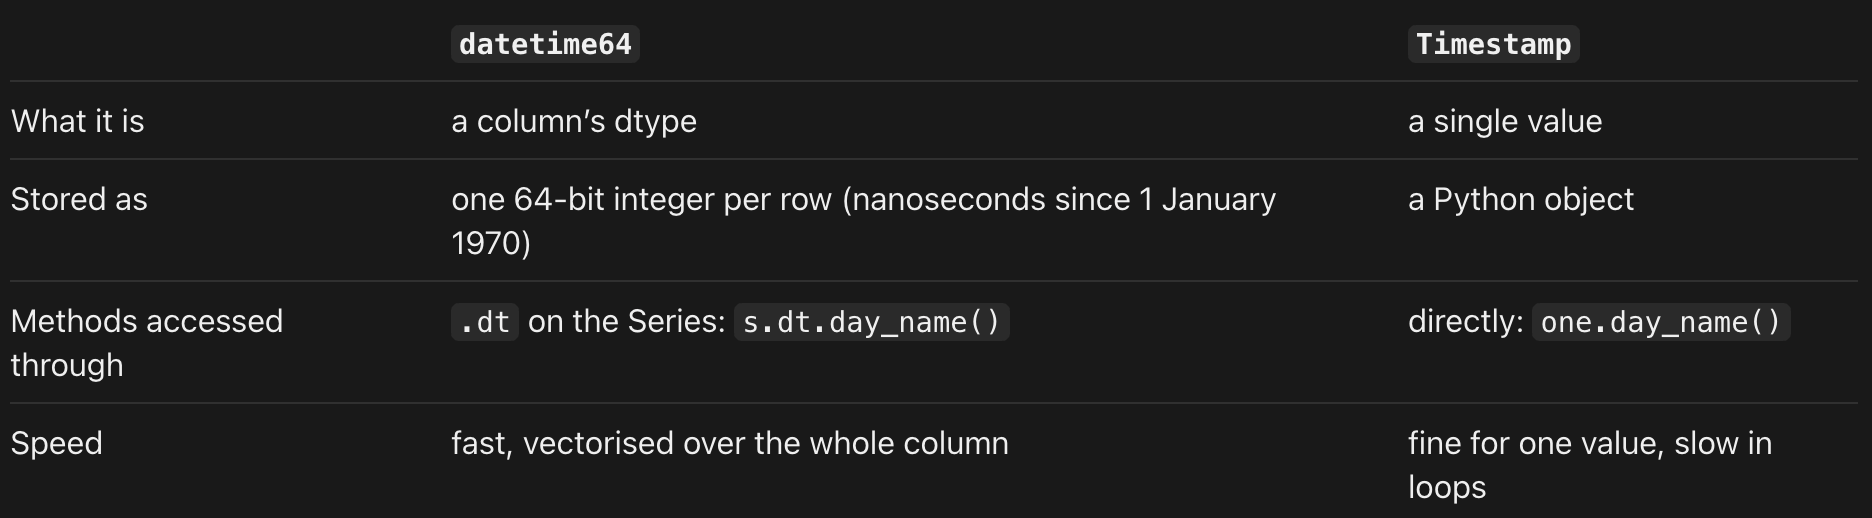

In [601]:
# series is a 'datetime64' object
print(eth_df['Date'].dtype)

# single date is a 'timestamp' object
print(type(eth_df.loc[0, 'Date']))

datetime64[ns]
<class 'pandas._libs.tslibs.timestamps.Timestamp'>


Once our time data is formatted as 'datetime64', we can then apply datetime methods. 

`day_name()` returns the name of the day of the date. 

In [602]:
# using day_name() on 'timestamp' object
print(eth_df.loc[0, 'Date'].day_name())

# using day_name() on 'datetime64' object (call .dt before method)
print(eth_df['Date'].dt.day_name())

Friday
0          Friday
1          Friday
2          Friday
3          Friday
4          Friday
           ...   
23669    Saturday
23670    Saturday
23671    Saturday
23672    Saturday
23673    Saturday
Name: Date, Length: 23674, dtype: object


In [603]:
# adding a column for 'day of the week'
eth_df['DayOfWeek'] = eth_df['Date'].dt.day_name()
eth_df

,Date,Symbol,Open,High,Low,Close,Volume,DayOfWeek
0,2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93,Friday
1,2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09,Friday
2,2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday
3,2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
4,2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
...,...,...,...,...,...,...,...,...
23669,2017-07-01 15:00:00,ETHUSD,265.74,272.74,265.00,272.57,1500282.55,Saturday
23670,2017-07-01 14:00:00,ETHUSD,268.79,269.90,265.00,265.74,1702536.85,Saturday
23671,2017-07-01 13:00:00,ETHUSD,274.83,274.93,265.00,268.79,3010787.99,Saturday
23672,2017-07-01 12:00:00,ETHUSD,275.01,275.01,271.00,274.83,824362.87,Saturday


### Viewing earliest and latest dates

We can apply the following methods: 
* `min()`: earliest date
* `max()`: latest date

In [604]:
# earliest date
print(eth_df['Date'].min())

# latest date
print(eth_df['Date'].max())

2017-07-01 11:00:00
2020-03-13 20:00:00


### Time delta

While 'timestamp' is a data type that represents a **point in time**, 'timedelta' is a data type that represent the **duration (an amount of time)** between two 'timestamp' points. 

In [605]:
# finding the time delta between the latest and earliest date in eth_df
eth_df['Date'].max() - eth_df['Date'].min()

Timedelta('986 days 09:00:00')

### Filtering 

We can apply filters for dates in the **same way** we do for normal filtering. 

There are 2 types of data we can use to create filters:
* string data (general filtering)
* datetime data using `pd.to_datetime()` (more specific)

In [606]:
# method 1: creating filter for 2019 using strings
filt = (eth_df['Date'] >= '2019') & (eth_df['Date'] < '2020') # enter the date as a str
eth_df.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayOfWeek
1749,2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
1750,2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
1751,2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
1752,2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
1753,2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...,...
10504,2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
10505,2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
10506,2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday
10507,2019-01-01 01:00:00,ETHUSD,131.62,131.62,130.77,130.79,434917.99,Tuesday


In [607]:
# method 2: creating filters using 'datetime' values
filt = (eth_df['Date'] >= pd.to_datetime('2019-01-01')) & (eth_df['Date'] < pd.to_datetime('2020-01-01'))
eth_df.loc[filt]

,Date,Symbol,Open,High,Low,Close,Volume,DayOfWeek
1749,2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
1750,2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
1751,2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
1752,2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
1753,2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...,...
10504,2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
10505,2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
10506,2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday
10507,2019-01-01 01:00:00,ETHUSD,131.62,131.62,130.77,130.79,434917.99,Tuesday


Another method for filtering is by **setting the 'Date' as the index** of our dataframe.

* Apply `.loc` to find a **specific date** of interest
* Apply **slicing** with `.loc` to find a **range of dates** of interest

note: before slicing the data must **first be sorted in ascending order**.


In [608]:
# setting the 'Date' as index
eth_df.set_index('Date', inplace=True)
eth_df

,Symbol,Open,High,Low,Close,Volume,DayOfWeek
Date,,,,,,,
2020-03-13 20:00:00,ETHUSD,129.94,131.82,126.87,128.71,1940673.93,Friday
2020-03-13 19:00:00,ETHUSD,119.51,132.02,117.10,129.94,7579741.09,Friday
2020-03-13 18:00:00,ETHUSD,124.47,124.85,115.50,119.51,4898735.81,Friday
2020-03-13 17:00:00,ETHUSD,124.08,127.42,121.63,124.47,2753450.92,Friday
2020-03-13 16:00:00,ETHUSD,124.85,129.51,120.17,124.08,4461424.71,Friday
...,...,...,...,...,...,...,...
2017-07-01 15:00:00,ETHUSD,265.74,272.74,265.00,272.57,1500282.55,Saturday
2017-07-01 14:00:00,ETHUSD,268.79,269.90,265.00,265.74,1702536.85,Saturday
2017-07-01 13:00:00,ETHUSD,274.83,274.93,265.00,268.79,3010787.99,Saturday


In [609]:
# finding 2019 data only
eth_df.loc['2019']

,Symbol,Open,High,Low,Close,Volume,DayOfWeek
Date,,,,,,,
2019-12-31 23:00:00,ETHUSD,128.33,128.69,128.14,128.54,440678.91,Tuesday
2019-12-31 22:00:00,ETHUSD,128.38,128.69,127.95,128.33,554646.02,Tuesday
2019-12-31 21:00:00,ETHUSD,127.86,128.43,127.72,128.38,350155.69,Tuesday
2019-12-31 20:00:00,ETHUSD,127.84,128.34,127.71,127.86,428183.38,Tuesday
2019-12-31 19:00:00,ETHUSD,128.69,128.69,127.60,127.84,1169847.84,Tuesday
...,...,...,...,...,...,...,...
2019-01-01 04:00:00,ETHUSD,130.75,133.96,130.74,131.96,2791135.37,Tuesday
2019-01-01 03:00:00,ETHUSD,130.06,130.79,130.06,130.75,503732.63,Tuesday
2019-01-01 02:00:00,ETHUSD,130.79,130.88,129.55,130.06,838183.43,Tuesday


In [610]:
# sort the data
eth_df.sort_index(inplace=True)

# finding a range of data
eth_df.loc['2020-01':'2020-02']

,Symbol,Open,High,Low,Close,Volume,DayOfWeek
Date,,,,,,,
2020-01-01 00:00:00,ETHUSD,128.54,128.54,128.12,128.34,245119.91,Wednesday
2020-01-01 01:00:00,ETHUSD,128.34,130.14,128.32,130.14,635419.40,Wednesday
2020-01-01 02:00:00,ETHUSD,130.14,130.50,129.91,130.37,396315.72,Wednesday
2020-01-01 03:00:00,ETHUSD,130.37,130.44,129.38,129.57,496704.23,Wednesday
2020-01-01 04:00:00,ETHUSD,129.57,130.00,129.50,129.56,702786.82,Wednesday
...,...,...,...,...,...,...,...
2020-02-29 19:00:00,ETHUSD,225.09,225.85,223.87,225.31,1250856.20,Saturday
2020-02-29 20:00:00,ETHUSD,225.31,225.33,223.50,224.63,511648.65,Saturday
2020-02-29 21:00:00,ETHUSD,224.63,225.14,222.74,223.48,561158.03,Saturday


Being able to slice the dates allow us to apply **aggregation methods** on the data to analyze it.  

In [611]:
# finding the mean closing price over the 2 months 
eth_df.loc['2020-01':'2020-02']['Close'].mean()

np.float64(195.1655902777778)

### Resampling time data

`resample()` regroups time series into **new time intervals**. Returns a *Resampler* object (time-based version of the 'groupby' object). We can apply **aggregation functions** on the returned *Resampler* object.

We can pass the following **frequency strings** as a parameter for the new time interval we are interested in. 

Some common frq strings include: 
* 'h': one hour
* 'D': one calendar day
* 'W': one week 

In [612]:
# finding the high of a single day
eth_df.loc['2020-01-01']['High'].max()

132.68

In [613]:
# resampling the data by day and apply max()
highs = eth_df['High'].resample('D').max()
highs

Date
2017-07-01    279.99
2017-07-02    293.73
2017-07-03    285.00
2017-07-04    282.83
2017-07-05    274.97
               ...  
2020-03-09    208.65
2020-03-10    206.28
2020-03-11    202.98
2020-03-12    195.64
2020-03-13    148.00
Freq: D, Name: High, Length: 987, dtype: float64

In [614]:
# finding the high for one specific day
highs.loc['2020-01-01']

np.float64(132.68)

We can also apply `resample()` to the entire dataframe.

In [616]:
eth_df.resample('W').mean(numeric_only=True) # numeric_only: lets mean be applied on only numeric values

,Open,High,Low,Close,Volume
Date,,,,,
2017-07-02,268.066486,271.124595,264.819730,268.202162,2.185035e+06
2017-07-09,261.337024,262.872917,259.186190,261.062083,1.337349e+06
2017-07-16,196.193214,199.204405,192.722321,195.698393,2.986756e+06
2017-07-23,212.351429,215.779286,209.126310,212.783750,4.298593e+06
2017-07-30,203.496190,205.110357,201.714048,203.309524,1.581729e+06
...,...,...,...,...,...
2020-02-16,255.021667,257.255238,252.679762,255.198452,2.329087e+06
2020-02-23,265.220833,267.263690,262.948512,265.321905,1.826094e+06
2020-03-01,236.720536,238.697500,234.208750,236.373988,2.198762e+06


To apply specific **aggregation methods** to specific columns instead of one on the whole dataframe, we again use the `agg()` method. 

In [617]:
# applying different aggregation methods to each column
eth_df.resample('W').agg({'Close': 'mean',
                          'High': 'max',
                          'Low': 'min',
                          'Volume': 'sum'})

,Close,High,Low,Volume
Date,,,,
2017-07-02,268.202162,293.73,253.23,8.084631e+07
2017-07-09,261.062083,285.00,231.25,2.246746e+08
2017-07-16,195.698393,240.33,130.26,5.017750e+08
2017-07-23,212.783750,249.40,153.25,7.221637e+08
2017-07-30,203.309524,229.99,178.03,2.657305e+08
...,...,...,...,...
2020-02-16,255.198452,290.00,216.31,3.912867e+08
2020-02-23,265.321905,287.13,242.36,3.067838e+08
2020-03-01,236.373988,278.13,209.26,3.693920e+08


### Plotting time series data

With time series data, the best way to visualise them is using plots. 

Pandas has some plotting methods, although it is important to note that pandas simply passes the data into `Matplotlib` which does the actual drawing.



<Axes: xlabel='Date'>

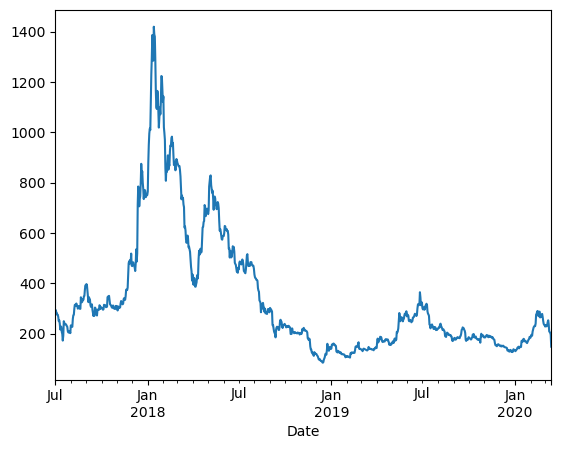

In [ ]:
# line graph of high by day
highs.plot()